# 03 — Entraîner un modèle de correction

**Objectif :** prédire, heure par heure, ce que mesurerait la station de référence, à partir de la mesure brute du capteur et de son contexte (météo, heure, passé récent, voisins).

**Comment on juge un modèle.** Le vrai usage, c'est de corriger un capteur **loin de toute station**. Le modèle ne doit donc jamais être noté sur une station qu'il a vue pendant l'apprentissage. On répartit les stations en 5 groupes (des « plis ») ; une station et tous ses capteurs restent toujours dans le même pli. On apprend sur 4 plis et on prédit le 5ᵉ, cinq fois de suite (`GroupKFold` de scikit-learn). Chaque prédiction vient ainsi d'un modèle qui n'a jamais vu la station concernée.

Si on avait découpé au hasard par heure, le modèle aurait vu les autres heures de la même station : il aurait « reconnu » le lieu et paru meilleur qu'il ne l'est.

**Comment on travaille.** Pour itérer vite, on compare les modèles sur un **échantillon de 20 % des stations** (tirées au hasard, graine fixe, toujours les mêmes). Une fois les choix faits, `scripts/04_entrainer.py` refait exactement les mêmes calculs sur toutes les stations ; le notebook 04 vérifie que les conclusions de l'échantillon tiennent à grande échelle.

Chaque essai ajoute une ligne au journal `reports/runs.csv` (date, modèle, variables, réglages, résultats).

**Les variables** (construites par `scripts/03_construire_variables.py`, 14 variables sur 17 colonnes) :

| famille | variables | idée |
|---|---|---|
| capteur | `pm25`, `pm10`, `rapport_pm25_pm10`, `n_mesures` | la mesure brute ; le rapport PM2.5/PM10 change quand les particules gonflent avec l'humidité |
| météo (DWD) | `humidite`, `temperature`, `point_de_rosee` | l'effet de l'humidité vu au notebook 02 |
| temps | heure, mois, jour de la semaine (en sinus/cosinus) | cycles du trafic et du chauffage ; le codage en cercle met 23 h à côté de 0 h |
| passé | `pm25_moy_3h`, `pm25_moy_24h` | moyenne du capteur sur les 3 et 24 dernières heures (jamais l'avenir) |
| voisins | `mediane_voisins`, `ecart_voisins` | niveau du quartier, et écart du capteur à ce niveau (en log) |

On n'utilise **jamais** la référence de la station comme variable : elle n'existe pas là où on veut corriger.

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from aircalib import modeles as M
from aircalib import parametres as P
from aircalib.metriques import resume, resume_par, stats_regression
from aircalib.variables import FAMILLES, VARIABLES

pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIGURES = P.RAPPORTS / "figures"
PERIMETRE = "échantillon : 20 % des stations"

table = pl.read_parquet(P.dossier_donnees() / "variables" / "table.parquet")
ech = M.echantillon_de_stations(table)
print(
    f"échantillon : {ech['station'].n_unique()} stations sur {table['station'].n_unique()}, "
    f"{ech['capteur'].n_unique()} capteurs, {ech.height:,} heures"
)
print(ech.group_by("pli").agg(stations=pl.col("station").n_unique(), heures=pl.len()).sort("pli"))

COLONNES = [
    "heures",
    "rmse",
    "mae",
    "r2_median_par_paire",
    "pente_mediane_par_paire",
    "pct_epa_horaire",
    "pct_epa_journalier",
]
essais = {}


def noter(nom, predictions):
    """Garde les chiffres des paires saines pour le tableau de comparaison."""
    chiffres = resume(predictions.filter(pl.col("paire_saine")))
    essais[nom] = {k: chiffres[k] for k in COLONNES}
    return pl.DataFrame([{"modele": nom} | essais[nom]]).with_columns(pl.col(pl.Float64).round(3))

échantillon : 35 stations sur 179, 81 capteurs, 745,815 heures
┌─────┬──────────┬────────┐
│ pli ┆ stations ┆ heures │
│ --- ┆ ---      ┆ ---    │
│ i64 ┆ u32      ┆ u32    │
╞═════╪══════════╪════════╡
│ 0   ┆ 4        ┆ 110647 │
│ 1   ┆ 10       ┆ 268980 │
│ 2   ┆ 6        ┆ 124744 │
│ 3   ┆ 11       ┆ 131786 │
│ 4   ┆ 4        ┆ 109658 │
└─────┴──────────┴────────┘


L'échantillon contient 35 stations sur 179, 81 capteurs et 745 815 heures. Sur ces capteurs, 60 forment des paires saines notées.

Les plis sont inégaux : de 4 à 11 stations chacun, parce qu'une station peut avoir beaucoup de capteurs. Il faut garder en tête que, sur 60 paires, **une paire de plus ou de moins fait bouger le pourcentage EPA de 1,7 point**. Les petites différences entre modèles ne voudront donc pas dire grand-chose.

## 1. Point de départ : le capteur brut

Le « modèle 0 » ne corrige rien : la prédiction est la mesure du capteur. C'est la ligne de base à battre.

In [2]:
brut = M.evaluer("0_capteur_brut", PERIMETRE, ech, M.capteur_brut, ["pm25"], {})
noter("0_capteur_brut", brut)

modele,heures,rmse,mae,r2_median_par_paire,pente_mediane_par_paire,pct_epa_horaire,pct_epa_journalier
str,i64,f64,f64,f64,f64,f64,f64
"""0_capteur_brut""",611221,7.086,4.497,0.711,0.579,21.667,32.759


Le capteur brut obtient :
- un RMSE de 7,1 µg/m³ et un MAE de 4,5 ;
- un R² médian de 0,71 et une pente médiane de 0,58 ;
- **21,7 % des paires EPA** (13 sur 60) en horaire, et 32,8 % en journalier.

C'est proche de ce qu'on a mesuré sur toutes les paires saines au notebook 02 (25 % et 41 %) : l'échantillon est raisonnablement représentatif de l'« avant ».

## 2. La calibration classique : une régression linéaire

C'est ce qu'on trouve le plus souvent dans la littérature : $\text{référence} \approx a + b\cdot\text{PM}_{\text{brut}} + c\cdot\text{humidité} + d\cdot\text{température}$.

In [3]:
lineaire = M.evaluer(
    "1_regression_lineaire", PERIMETRE, ech, M.regression_lineaire, ["pm25", "humidite", "temperature"], {}
)
noter("1_regression_lineaire", lineaire)

modele,heures,rmse,mae,r2_median_par_paire,pente_mediane_par_paire,pct_epa_horaire,pct_epa_journalier
str,i64,f64,f64,f64,f64,f64,f64
"""1_regression_lineaire""",611221,5.812,3.626,0.672,0.437,8.333,10.345


L'erreur baisse :
- le RMSE passe de 7,1 à 5,8 ;
- le MAE passe de 4,5 à 3,6.

Mais le pourcentage EPA s'effondre : **8,3 % des paires** (5 sur 60), avec une pente médiane de 0,44. La régression fait moins d'erreurs en moyenne, mais elle est moins bonne au sens de l'EPA. C'est un paradoxe qu'il faut comprendre avant d'aller plus loin.

On creuse un peu pour comprendre pourquoi.

In [4]:
saines = ech.filter(pl.col("paire_saine"))
globale = stats_regression(lineaire.filter(pl.col("paire_saine")).with_columns(tout=pl.lit(1)), ["tout"])
print(
    f"régression linéaire, toutes heures : R² = {globale['r2'][0]:.2f}, pente EPA = {globale['pente'][0]:.2f}"
)
seuil = saines["pm25"].quantile(0.99)
cas = {
    "toutes les heures": saines,
    f"sans le 1 % le plus haut (PM2.5 brut > {seuil:.0f})": saines.filter(pl.col("pm25") <= seuil),
}
for nom, donnees in cas.items():
    coefs = (
        M.LinearRegression()
        .fit(M.matrice(donnees, ["pm25", "humidite", "temperature"]), donnees["reference"].to_numpy())
        .coef_
    )
    print(f"{nom:45s} coefficient du PM2.5 brut = {coefs[0]:.2f}")
print(f"PM2.5 brut : médiane {saines['pm25'].median():.1f}, max {saines['pm25'].max():.0f} µg/m³")
print(f"station : max {saines['reference'].max():.0f} µg/m³")

régression linéaire, toutes heures : R² = 0.43, pente EPA = 0.43
toutes les heures                             coefficient du PM2.5 brut = 0.68
sans le 1 % le plus haut (PM2.5 brut > 33)    coefficient du PM2.5 brut = 0.86
PM2.5 brut : médiane 3.2, max 475 µg/m³
station : max 258 µg/m³


**Pourquoi « pente EPA ≈ R² ».** Un modèle ajusté par moindres carrés (régression linéaire, mais aussi LightGBM, qui minimise la même erreur quadratique) produit des prédictions $\hat y$ telles que $\mathrm{cov}(\hat y, y) \approx \mathrm{var}(\hat y)$. Or la pente de l'EPA est celle de la régression de $\hat y$ sur $y$ :

$$\text{pente} = \frac{\mathrm{cov}(\hat y, y)}{\mathrm{var}(y)} \approx \frac{\mathrm{var}(\hat y)}{\mathrm{var}(y)} = R^2$$

On le voit ci-dessus : sur toutes les heures, le $R^2$ de la régression vaut 0,43, et sa pente EPA aussi. Un modèle qui n'explique que 43 % de la variance « tasse » ses prédictions vers la moyenne : quand la pollution monte de 10 µg/m³, il ne prédit qu'une hausse de 4,3. **Pour avoir une pente proche de 1, il faut un $R^2$ élevé.** Réduire le RMSE ne suffit pas.

**Pourquoi le $R^2$ de la régression est si bas.** Le PM2.5 brut a une médiane de 3,2 µg/m³ mais monte jusqu'à 475, alors que la station ne dépasse jamais 258. Ces quelques valeurs extrêmes tirent la droite : le coefficient du PM2.5 brut vaut 0,68, et 0,86 si on retire le 1 % des heures les plus hautes. Le même coefficient s'applique en plus à toutes les paires, qu'elles soient près d'une route ou en forêt, par air sec ou humide.

**Décision :** la régression linéaire reste notre point de comparaison, mais il faut un modèle qui puisse appliquer une correction différente selon l'humidité et le niveau de pollution, et qui soit peu sensible aux valeurs extrêmes.

## 3. LightGBM avec les réglages par défaut

LightGBM est un modèle d'arbres de décision construits les uns après les autres (*gradient boosting*) : chaque arbre corrige les erreurs des précédents. Il peut apprendre des effets non linéaires (l'humidité qui ne compte qu'au-dessus de 70 %, par exemple) et des interactions entre variables, sans qu'on les écrive à la main. Il accepte aussi les valeurs manquantes (des heures sans voisins, par exemple). On l'essaie d'abord avec ses réglages par défaut (100 arbres de 31 feuilles).

In [5]:
defaut = M.lightgbm(VARIABLES)
lgb_defaut = M.evaluer("2_lightgbm", PERIMETRE, ech, defaut, VARIABLES, {"arbres": 100})
importance = M.validation_croisee.importance
noter("2_lightgbm", lgb_defaut)

modele,heures,rmse,mae,r2_median_par_paire,pente_mediane_par_paire,pct_epa_horaire,pct_epa_journalier
str,i64,f64,f64,f64,f64,f64,f64
"""2_lightgbm""",611221,4.785,2.783,0.809,0.747,53.333,68.966


Avec les réglages par défaut, LightGBM obtient :
- un RMSE de 4,8 et un MAE de 2,8 ;
- un R² médian de 0,81 et une pente médiane de 0,75 ;
- **53,3 % des paires EPA** (32 sur 60) en horaire, 69,0 % en journalier.

C'est un gros saut par rapport au capteur brut (21,7 %) et à la régression (8,3 %). Comme prévu, un $R^2$ plus haut donne une pente plus proche de 1.

## 4. Et des variables sur la station ?

Dans notre premier essai, on avait ajouté deux variables sur la station : son type (fond, trafic, industrielle) et la distance capteur–station. En y repensant, c'est incohérent avec l'usage visé : **là où on veut corriger un capteur, il n'y a pas de station**, donc ni type ni distance. On vérifie sur l'échantillon ce qu'on perd en les retirant.

In [6]:
TYPES = {"background": 0.0, "industrial": 1.0, "traffic": 2.0}
ech_station = ech.with_columns(type_station_code=pl.col("type_station").replace_strict(TYPES, default=None))
AVEC_STATION = VARIABLES + ["type_station_code", "distance_km"]
lgb_station = M.evaluer(
    "2_lightgbm_avec_station", PERIMETRE, ech_station, M.lightgbm(AVEC_STATION), AVEC_STATION, {"arbres": 100}
)
noter("2_lightgbm_avec_station", lgb_station)
pl.DataFrame([{"modele": k} | v for k, v in essais.items() if k.startswith("2_")]).with_columns(
    pl.col(pl.Float64).round(3)
)

modele,heures,rmse,mae,r2_median_par_paire,pente_mediane_par_paire,pct_epa_horaire,pct_epa_journalier
str,i64,f64,f64,f64,f64,f64,f64
"""2_lightgbm""",611221,4.785,2.783,0.809,0.747,53.333,68.966
"""2_lightgbm_avec_station""",611221,4.943,2.962,0.811,0.805,58.333,72.414


Avec les deux variables de station, on gagne 3 paires sur 60 (58,3 % contre 53,3 %), mais le RMSE et le MAE sont *moins bons* (4,94 contre 4,79, et 2,96 contre 2,78).

**Ce que ça veut dire :** le gain tient en 3 paires, c'est-à-dire à peu près le bruit de l'échantillon, et l'erreur moyenne augmente.

**Décision :** on retire ces deux variables. Même si elles avaient aidé, on ne pourrait pas s'en servir pour un capteur loin de toute station. La distance reste dans la table, mais seulement pour découper les résultats par distance au notebook 04.

## 5. Deux réglages à la main

Plutôt qu'une recherche automatique sur des dizaines de combinaisons, on essaie deux changements dont on comprend l'effet :
- **réglage 1** : apprendre plus lentement (`learning_rate` 0,05 au lieu de 0,1) avec 5 fois plus d'arbres. C'est souvent un peu meilleur, mais 5 fois plus long ;
- **réglage 2** : des arbres plus grands (63 feuilles) mais avec au moins 200 heures par feuille, pour capter plus de détails sans apprendre le bruit.

In [7]:
# Réglage 1 : apprendre plus lentement, avec plus d'arbres (souvent un peu meilleur, 5 fois plus long).
REGLAGE_1 = {"learning_rate": 0.05}
lgb_1 = M.evaluer(
    "3_lightgbm_reglage_1",
    PERIMETRE,
    ech,
    M.lightgbm(VARIABLES, REGLAGE_1, 500),
    VARIABLES,
    REGLAGE_1 | {"arbres": 500},
)
# Réglage 2 : des arbres plus grands mais des feuilles plus peuplées (plus de détails, moins de bruit appris).
REGLAGE_2 = {"num_leaves": 63, "min_data_in_leaf": 200}
lgb_2 = M.evaluer(
    "3_lightgbm_reglage_2",
    PERIMETRE,
    ech,
    M.lightgbm(VARIABLES, REGLAGE_2),
    VARIABLES,
    REGLAGE_2 | {"arbres": 100},
)
noter("3_lightgbm_reglage_1", lgb_1)
noter("3_lightgbm_reglage_2", lgb_2)
pl.DataFrame([{"modele": k} | v for k, v in essais.items()]).with_columns(pl.col(pl.Float64).round(3))

modele,heures,rmse,mae,r2_median_par_paire,pente_mediane_par_paire,pct_epa_horaire,pct_epa_journalier
str,i64,f64,f64,f64,f64,f64,f64
"""0_capteur_brut""",611221,7.086,4.497,0.711,0.579,21.667,32.759
"""1_regression_lineaire""",611221,5.812,3.626,0.672,0.437,8.333,10.345
"""2_lightgbm""",611221,4.785,2.783,0.809,0.747,53.333,68.966
"""2_lightgbm_avec_station""",611221,4.943,2.962,0.811,0.805,58.333,72.414
"""3_lightgbm_reglage_1""",611221,4.754,2.76,0.808,0.76,55.0,70.69
"""3_lightgbm_reglage_2""",611221,4.733,2.767,0.805,0.76,56.667,68.966


- **Réglage 1 :** 55,0 % (une paire de plus que les réglages par défaut), pour 5 fois plus de temps de calcul.
- **Réglage 2 :** 56,7 % (deux paires de plus).

Les RMSE sont à peu près identiques (4,75 et 4,73 contre 4,79).

**Ce que ça veut dire :** les réglages ne changent presque rien. Une ou deux paires sur 60, c'est dans le bruit de l'échantillon. Ce qui limite le modèle n'est pas son réglage, c'est l'information qu'on lui donne.

**Décision :** on garde les **réglages par défaut**, les plus simples et les plus rapides. Le script 04 refait le réglage 1 sur toutes les stations pour vérifier ce choix.

## 6. Les voisins servent-ils vraiment ? (ablation)

On réentraîne le même LightGBM **sans** les deux variables de voisins, puis on compare les heures qui ont des voisins et celles qui n'en ont pas.

In [8]:
SANS_VOISINS = [v for v in VARIABLES if v not in FAMILLES["voisins"]]
lgb_sans = M.evaluer(
    "4_lightgbm_sans_voisins", PERIMETRE, ech, M.lightgbm(SANS_VOISINS), SANS_VOISINS, {"arbres": 100}
)
noter("4_lightgbm_sans_voisins", lgb_sans)
comparaison = []
for nom, pred in [("avec les variables voisins", lgb_defaut), ("sans les variables voisins", lgb_sans)]:
    par = resume_par(pred.filter(pl.col("paire_saine")), "a_des_voisins")
    comparaison.append(
        par.select("a_des_voisins", "heures", "rmse", "pct_epa_horaire").with_columns(modele=pl.lit(nom))
    )
pl.concat(comparaison).with_columns(pl.col(pl.Float64).round(2))

a_des_voisins,heures,rmse,pct_epa_horaire,modele
bool,i64,f64,f64,str
false,222155,6.04,17.24,"""avec les variables voisins"""
true,389066,3.9,70.45,"""avec les variables voisins"""
false,222155,5.63,20.69,"""sans les variables voisins"""
true,389066,4.29,40.91,"""sans les variables voisins"""


Le tableau compare les deux modèles (avec et sans les variables de voisins), heure par heure, selon que le capteur a des voisins ou non.

- **Heures avec voisins** (64 % des heures de l'échantillon) : 70,5 % des paires EPA avec les variables de voisins, contre 40,9 % sans elles, soit **30 points de plus**. Le RMSE passe aussi de 4,29 à 3,90. Les voisins sont de loin la variable la plus utile qu'on ait ajoutée.
- **Heures sans voisins** (36 %) : c'est le point faible. Le modèle complet n'y fait que 17,2 % (RMSE 6,04), et le modèle *sans* variables de voisins fait mieux sur les deux critères : 20,7 % et un RMSE de 5,63.

**Pourquoi.** Le modèle complet a appris surtout sur des heures avec voisins, et il s'appuie beaucoup sur la médiane des voisins. Quand elle manque, LightGBM envoie l'heure dans une branche « par défaut », apprise sur moins d'exemples. Le modèle sans voisins, lui, a appris à s'en passer sur toutes les heures.

**Décision :** plutôt que de chercher un modèle plus compliqué, on **combine les deux** :
- le modèle complet quand le capteur a au moins 3 voisins ;
- le modèle sans voisins sinon.

On sait à l'avance si une heure a des voisins, donc ce choix n'utilise jamais la station. Il ne demande aucun entraînement supplémentaire (fonction `combiner` dans `src/aircalib/modeles.py`).

In [9]:
combine = M.combiner(lgb_defaut, lgb_sans)
M.noter_essai(
    "5_lightgbm_combine", PERIMETRE, VARIABLES, {"sans voisins": "4_lightgbm_sans_voisins"}, combine, 0.0
)
noter("5_lightgbm_combine", combine)
pl.DataFrame([{"modele": k} | v for k, v in essais.items()]).with_columns(pl.col(pl.Float64).round(3))

modele,heures,rmse,mae,r2_median_par_paire,pente_mediane_par_paire,pct_epa_horaire,pct_epa_journalier
str,i64,f64,f64,f64,f64,f64,f64
"""0_capteur_brut""",611221,7.086,4.497,0.711,0.579,21.667,32.759
"""1_regression_lineaire""",611221,5.812,3.626,0.672,0.437,8.333,10.345
"""2_lightgbm""",611221,4.785,2.783,0.809,0.747,53.333,68.966
"""2_lightgbm_avec_station""",611221,4.943,2.962,0.811,0.805,58.333,72.414
"""3_lightgbm_reglage_1""",611221,4.754,2.76,0.808,0.76,55.0,70.69
"""3_lightgbm_reglage_2""",611221,4.733,2.767,0.805,0.76,56.667,68.966
"""4_lightgbm_sans_voisins""",611221,4.821,2.958,0.761,0.632,35.0,56.897
"""5_lightgbm_combine""",611221,4.603,2.691,0.819,0.747,53.333,70.69


Le modèle combiné obtient :
- le **meilleur RMSE** de tous nos essais (4,60, contre 4,79 pour le LightGBM complet) ;
- le meilleur MAE (2,69) et le meilleur R² médian (0,82) ;
- 70,7 % des paires EPA en journalier, contre 69,0 % pour le LightGBM complet ;
- le même pourcentage en horaire (53,3 %).

**Décision : c'est notre modèle retenu** (`5_lightgbm_combine`). L'échantillon ne permet pas de mesurer son gain sur le pourcentage EPA horaire (quelques paires au mieux) ; le notebook 04 le vérifie sur toutes les stations.

## 7. Ce que le modèle utilise

L'importance d'une variable est ici la part du « gain » total, c'est-à-dire de combien elle a réduit l'erreur, en moyenne sur les 5 plis (LightGBM complet, partie 3).

variable,pourcentage
str,f64
"""pm10""",48.8
"""mediane_voisins""",21.3
"""pm25""",8.3
"""humidite""",3.5
"""point_de_rosee""",3.1
"""rapport_pm25_pm10""",2.6
"""mois_sin""",2.6
"""mois_cos""",1.8


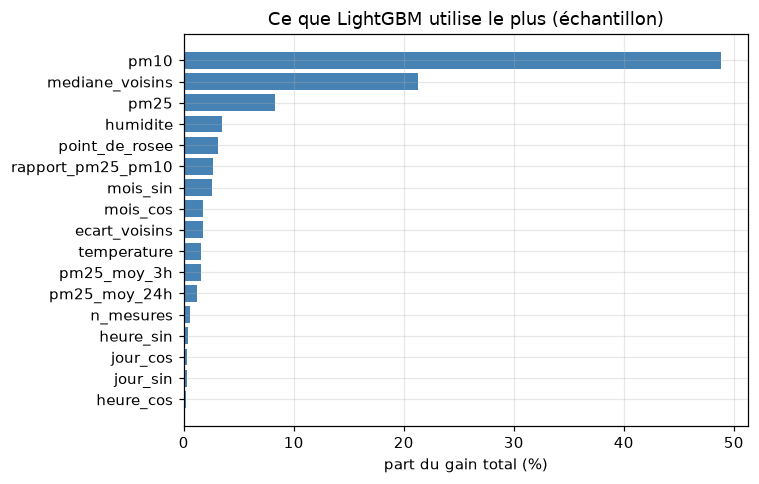

In [10]:
imp = pl.DataFrame(list(importance.items()), schema=["variable", "part_du_gain"], orient="row")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp["variable"][::-1], 100 * imp["part_du_gain"][::-1], color="steelblue")
ax.set_xlabel("part du gain total (%)")
ax.set_title("Ce que LightGBM utilise le plus (échantillon)")
fig.tight_layout()
fig.savefig(FIGURES / "03_importance.png")
imp.head(8).with_columns(pourcentage=(100 * pl.col("part_du_gain")).round(1)).drop("part_du_gain")

- Le PM10 du capteur arrive en tête (49 % du gain), devant le PM2.5 (8 %). Il ne faut pas en conclure que le PM10 compte plus que le PM2.5 « physiquement » : les deux canaux du SDS011 portent presque la même information, et l'arbre utilise l'un ou l'autre.
- La **médiane des voisins** arrive deuxième (21 %), ce qui confirme l'ablation.
- L'humidité, le point de rosée et le rapport PM2.5/PM10 font ensemble environ 9 %. C'est peu en gain, mais ce sont eux qui modulent la correction selon l'humidité de l'air (notebook 02).
- Le mois compte un peu (environ 4 %) : sans doute la composition des particules, qui change avec les saisons (chauffage au bois en hiver).

## Ce qu'on retient

- **La régression linéaire fait baisser l'erreur moyenne, mais échoue sur les cibles EPA.** La pente EPA d'un modèle des moindres carrés est à peu près son $R^2$, et les valeurs extrêmes du capteur tirent ce $R^2$ vers le bas.
- **LightGBM avec les réglages par défaut** fait passer l'échantillon de 22 % à 53 % de paires EPA. Les réglages manuels n'apportent rien de mesurable : on garde les réglages par défaut.
- **Pas de variable sur la station :** elle n'existe pas là où on veut corriger.
- **Les voisins sont le levier principal** (+30 points sur les heures où ils existent). Le point faible est l'heure sans voisins.
- **Le modèle retenu combine** le LightGBM complet (avec voisins) et le LightGBM sans voisins (heures sans voisins).

Les chiffres de l'échantillon sont plus bas que ce qu'on peut espérer sur toutes les stations : chaque modèle apprend sur moins de 30 stations, et 36 % des heures de l'échantillon n'ont pas de voisins. Ce qu'on retient ici, c'est **l'ordre des modèles et le sens de nos choix**, pas les chiffres eux-mêmes.

Les mêmes modèles sont maintenant entraînés sur toutes les stations : `python scripts/04_entrainer.py` (environ une minute). Le notebook 04 présente les résultats.